# Sales Drivers and Overstock Diagnosis: Advanced Analysis

This notebook goes beyond the SQL queries (`01_sql/05_analysis.sql`) and the Excel report (`02_excel/`). It explains **why** revenue moved and **what** the stock position means:

1. Revenue trend and a price-volume-mix bridge (Q1)
2. Product concentration: ABC classes, Pareto curve and Gini coefficient (Q5)
3. Inventory: months of stock by store and category, a stock rebalancing scenario, and stock age (Q2, Q6)
4. Discounts: a permutation test of whether bigger discounts sell more (Q7)
5. Basket analysis: which categories are bought together

**Data:** all 9 raw CSV files in `data_and_questions/raw_data/`, loaded in full (no sampling).
**Libraries:** numpy, pandas, matplotlib. Charts are saved to `charts/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Paths are relative to this notebook (process/03_python/)
RAW = Path("../../data_and_questions/raw_data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 120)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.family": "Arial",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})
NAVY, GREY, ORANGE = "#1F3864", "#A6A6A6", "#C55A11"
usd = mticker.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:,.0f}K")

## 0. Load and prepare the data

All 9 files are read in full. The text `NULL` in the CSV files is read as a missing value.

In [2]:
tables = ["brands", "categories", "customers", "order_items", "orders",
          "products", "staffs", "stocks", "stores"]
df = {t: pd.read_csv(RAW / f"{t}.csv", na_values="NULL") for t in tables}

for col in ["order_date", "required_date", "shipped_date"]:
    df["orders"][col] = pd.to_datetime(df["orders"][col])

# Full data: every row of every file is loaded (no sampling)
pd.Series({t: len(d) for t, d in df.items()}, name="rows").to_frame()

,rows
brands,9
categories,7
customers,1445
order_items,4722
orders,1615
products,321
staffs,10
stocks,939
stores,3


In [3]:
expected = {"brands": 9, "categories": 7, "customers": 1445, "order_items": 4722, "orders": 1615,
            "products": 321, "staffs": 10, "stocks": 939, "stores": 3}
assert all(len(df[t]) == n for t, n in expected.items()), "Row counts differ from the SQL import"
print("All 9 files loaded in full, and row counts match 02_import_data.sql")

All 9 files loaded in full, and row counts match 02_import_data.sql


The sales table follows the same rules as the SQL view `vw_sales` (`04_cleaning.sql`):

- completed orders only (`order_status = 4`), January 2016 to March 2018
- net revenue = quantity × list price × (1 − discount)

The totals are checked against the SQL results before any analysis.

In [4]:
products = (df["products"]
            .merge(df["brands"], on="brand_id")
            .merge(df["categories"], on="category_id"))

lines = (df["order_items"]
         .merge(df["orders"], on="order_id")
         .merge(products[["product_id", "product_name", "brand_name", "category_name", "model_year"]],
                on="product_id")
         .merge(df["stores"][["store_id", "store_name"]], on="store_id"))

lines["gross_revenue"] = lines["quantity"] * lines["list_price"]
lines["discount_amount"] = lines["gross_revenue"] * lines["discount"]
lines["net_revenue"] = lines["gross_revenue"] - lines["discount_amount"]
lines["order_month"] = lines["order_date"].dt.to_period("M")
lines["order_year"] = lines["order_date"].dt.year

# Same rule as vw_sales in 04_cleaning.sql: completed orders only
sales = lines[lines["order_status"] == 4].copy()

stock = (df["stocks"]
         .merge(products[["product_id", "product_name", "brand_name", "category_name", "model_year", "list_price"]],
                on="product_id")
         .merge(df["stores"][["store_id", "store_name"]], on="store_id"))
stock["stock_value"] = stock["quantity"] * stock["list_price"]

pd.Series({
    "order lines": len(sales),
    "orders": sales["order_id"].nunique(),
    "first date": sales["order_date"].min().date(),
    "last date": sales["order_date"].max().date(),
    "units": sales["quantity"].sum(),
    "net revenue": round(sales["net_revenue"].sum(), 2),
}).to_frame("completed sales")

,completed sales
order lines,4214
orders,1445
first date,2016-01-01
last date,2018-03-31
units,6318
net revenue,"6,662,615.24"


In [5]:
assert len(sales) == 4214 and sales["order_id"].nunique() == 1445
assert np.isclose(sales["net_revenue"].sum(), 6662615.24, atol=0.01)
assert len(stock) == 939 and stock["quantity"].sum() == 13511
print("pandas totals match vw_sales and vw_stock in SQL")

pandas totals match vw_sales and vw_stock in SQL


## 1. Revenue trend and drivers (Q1)

### 1.1 Monthly trend

A linear trend is fitted with `numpy.polyfit`, and a 3-month rolling average smooths the monthly noise.

Trend: +$5,397 net revenue per month (R^2 = 0.45)
Average month: $246,764, coefficient of variation: 25.8%


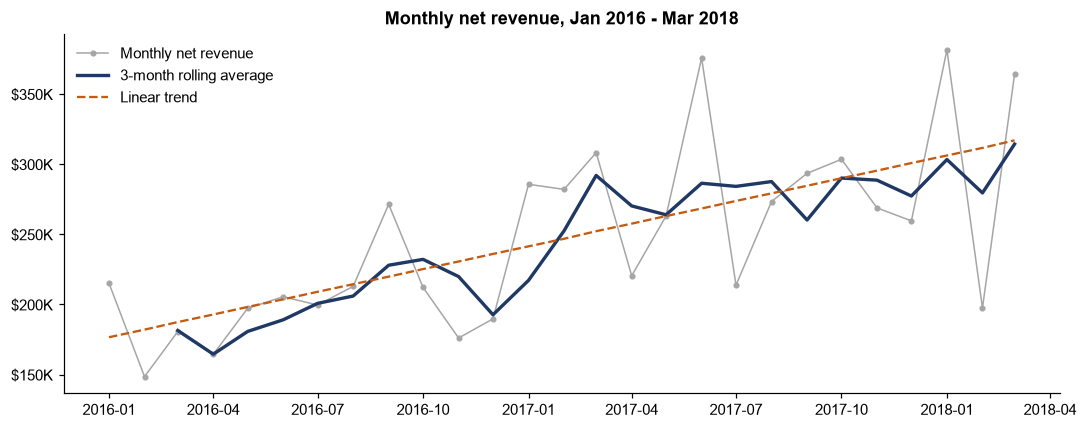

In [6]:
monthly = (sales.groupby("order_month")
           .agg(net_revenue=("net_revenue", "sum"),
                orders=("order_id", "nunique"),
                units=("quantity", "sum")))
monthly["rolling_3m"] = monthly["net_revenue"].rolling(3).mean()

# Linear trend fitted with numpy (x = month number)
x = np.arange(len(monthly))
slope, intercept = np.polyfit(x, monthly["net_revenue"], 1)
monthly["trend"] = intercept + slope * x
r = np.corrcoef(x, monthly["net_revenue"])[0, 1]

print(f"Trend: +${slope:,.0f} net revenue per month (R^2 = {r**2:.2f})")
print(f"Average month: ${monthly['net_revenue'].mean():,.0f}, "
      f"coefficient of variation: {monthly['net_revenue'].std() / monthly['net_revenue'].mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4))
xs = monthly.index.to_timestamp()
ax.plot(xs, monthly["net_revenue"], color=GREY, marker="o", ms=3, lw=1, label="Monthly net revenue")
ax.plot(xs, monthly["rolling_3m"], color=NAVY, lw=2.2, label="3-month rolling average")
ax.plot(xs, monthly["trend"], color=ORANGE, ls="--", lw=1.5, label="Linear trend")
ax.yaxis.set_major_formatter(usd)
ax.set_title("Monthly net revenue, Jan 2016 - Mar 2018")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(CHARTS / "01_monthly_trend.png", bbox_inches="tight")
plt.show()

**Result:** revenue grows by about **$5,400 per month** on trend (R² = 0.45). Monthly revenue is volatile (coefficient of variation 26%), so single months should not be read as a trend. The 3-month average is the better guide.

### 1.2 Price-volume-mix bridge, 2016 to 2017

Revenue grew by $974K (+41%). The bridge splits that growth into three effects:

- **Volume:** more units sold, valued at the 2016 average price per unit
- **Mix:** customers buying more of the higher-priced categories
- **Price:** a higher price within the same category

Road Bikes had no sales in 2016, so their 2017 price is used as the base price in the mix effect.

,USD
2016 revenue,"2,372,849.20"
Volume,"390,307.25"
Mix,"537,701.01"
Price,"46,115.19"
2017 revenue,"3,346,972.65"


Road Bikes (new in 2017) revenue: $1,004,578


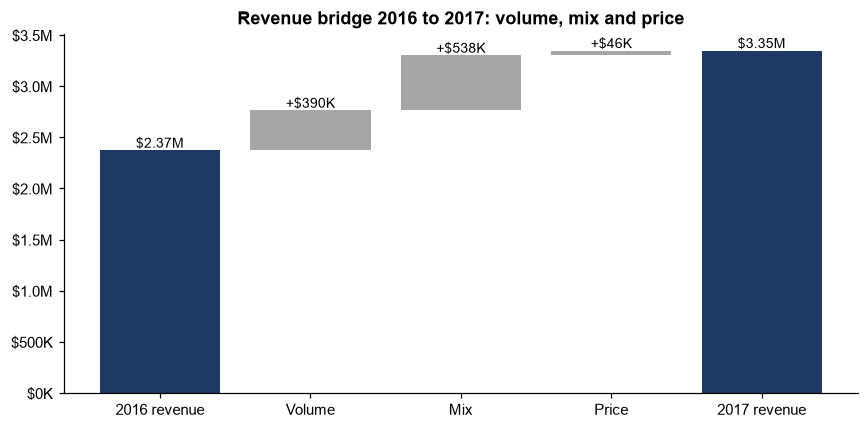

In [7]:
# Price-volume-mix bridge: why did revenue grow from 2016 to 2017?
# Volume = change in units at 2016 average price
# Mix    = change in category mix (at 2016 category prices)
# Price  = change in price within each category
cat_year = (sales[sales["order_year"].isin([2016, 2017])]
            .groupby(["order_year", "category_name"])
            .agg(units=("quantity", "sum"), revenue=("net_revenue", "sum"))
            .unstack(0, fill_value=0))
u16, u17 = cat_year["units"][2016], cat_year["units"][2017]
r16, r17 = cat_year["revenue"][2016], cat_year["revenue"][2017]
p16 = (r16 / u16.replace(0, np.nan))
p17 = (r17 / u17.replace(0, np.nan))

avg_p16 = r16.sum() / u16.sum()
volume = (u17.sum() - u16.sum()) * avg_p16
# categories not sold in 2016 (Road Bikes) are valued at their 2017 price in the mix effect
p_base = p16.fillna(p17)
mix = (u17 * p_base).sum() - u17.sum() * avg_p16
price = r17.sum() - (u17 * p_base).sum()

bridge = pd.Series({"2016 revenue": r16.sum(), "Volume": volume, "Mix": mix,
                    "Price": price, "2017 revenue": r17.sum()})
assert np.isclose(bridge.iloc[0] + volume + mix + price, bridge.iloc[-1])

display(bridge.to_frame("USD"))
road = r17.get("Road Bikes", 0)
print(f"Road Bikes (new in 2017) revenue: ${road:,.0f}")

fig, ax = plt.subplots(figsize=(8, 4))
steps = bridge.values
bottoms = [0, steps[0], steps[0] + steps[1], steps[0] + steps[1] + steps[2], 0]
colors = [NAVY, GREY, GREY, GREY, NAVY]
ax.bar(bridge.index, steps, bottom=bottoms, color=colors)
for i, (b, v) in enumerate(zip(bottoms, steps)):
    ax.text(i, b + v + 25000, f"${v/1e6:.2f}M" if i in (0, 4) else f"+${v/1e3:,.0f}K",
            ha="center", fontsize=9)
ax.yaxis.set_major_formatter(usd)
ax.set_title("Revenue bridge 2016 to 2017: volume, mix and price")
fig.tight_layout()
fig.savefig(CHARTS / "02_revenue_bridge.png", bbox_inches="tight")
plt.show()

**Result:** the largest driver is **mix (+$538K, 55% of the growth)**, followed by volume (+$390K) and price (+$46K). Road Bikes, a new category in 2017, brought $1.0M in their first year. Growth came mostly from selling more expensive bikes, not from more customers.

category_name,Mountain Bikes,Road Bikes,Cruisers Bicycles,Electric Bikes,Cyclocross Bicycles,Comfort Bicycles,Children Bicycles
order_year,,,,,,,
2016,48.90,0.00,15.60,11.70,13.80,6.40,3.70
2017,32.80,30.00,11.10,8.40,8.50,4.90,4.30
2018,24.40,34.20,13.40,18.50,3.10,3.30,3.10


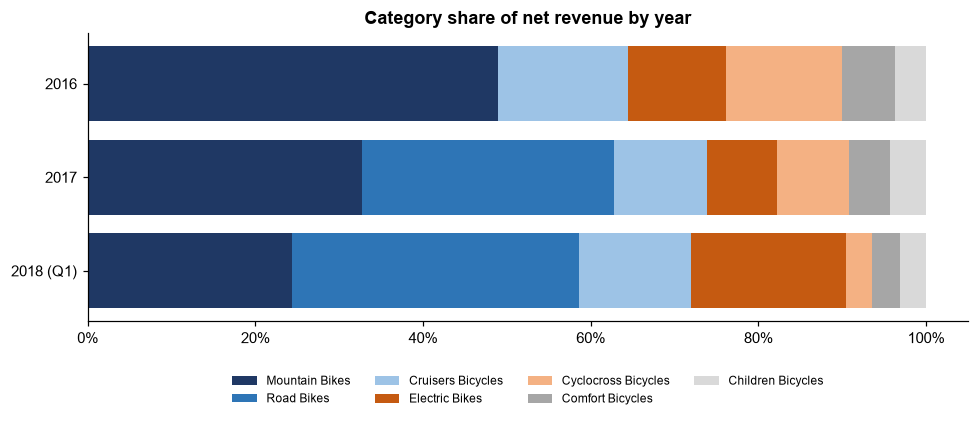

In [8]:
share = (sales.pivot_table(index="order_year", columns="category_name",
                           values="net_revenue", aggfunc="sum", fill_value=0))
share = share.div(share.sum(axis=1), axis=0)
share = share[share.mean().sort_values(ascending=False).index]
display((share * 100).round(1))

fig, ax = plt.subplots(figsize=(9, 4))
palette = ["#1F3864", "#2E75B6", "#9DC3E6", "#C55A11", "#F4B183", "#A6A6A6", "#D9D9D9"]
left = np.zeros(len(share))
labels = ["2016", "2017", "2018 (Q1)"]
for col, color in zip(share.columns, palette):
    ax.barh(labels, share[col], left=left, color=color, label=col)
    left += share[col].values
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Category share of net revenue by year")
ax.legend(ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.15), loc="upper center", fontsize=8)
fig.tight_layout()
fig.savefig(CHARTS / "03_category_mix.png", bbox_inches="tight")
plt.show()

**Result:** Mountain Bikes fell from 49% of revenue (2016) to 24% (Q1 2018), while Road Bikes rose from 0% to 34% and Electric Bikes reached 19% in Q1 2018. The business is shifting towards higher-priced bikes.

## 2. Product concentration (Q5)

Products are ranked by revenue and split into ABC classes (A = first 80% of revenue, B = next 15%, C = last 5%). The Gini coefficient measures how unequal revenue is across products.

,products,net_revenue,pct_products,pct_revenue
abc_class,,,,
A,52,"5,305,764.85",0.19,0.80
B,80,"1,022,181.30",0.29,0.15
C,146,"334,669.09",0.53,0.05


Gini coefficient of revenue across 278 products: 0.76


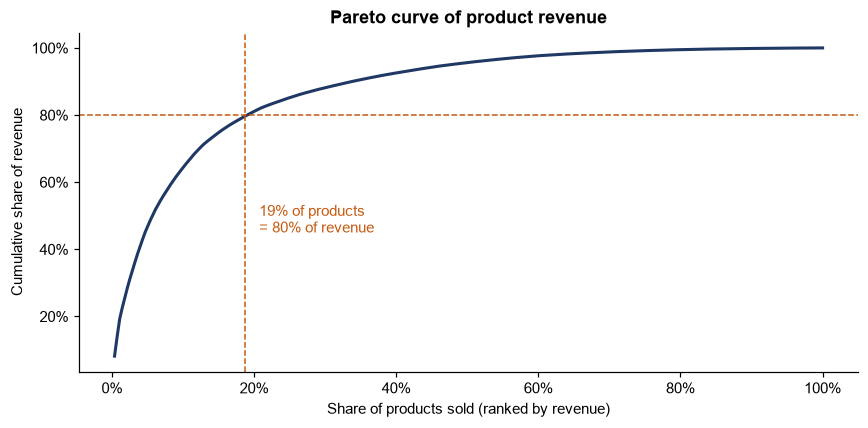

In [9]:
prod = (sales.groupby(["product_id", "product_name"])["net_revenue"].sum()
        .sort_values(ascending=False).reset_index())
prod["cum_share"] = prod["net_revenue"].cumsum() / prod["net_revenue"].sum()
prod["abc_class"] = np.select([prod["cum_share"] <= 0.80, prod["cum_share"] <= 0.95], ["A", "B"], "C")

abc = prod.groupby("abc_class").agg(products=("product_id", "count"), net_revenue=("net_revenue", "sum"))
abc["pct_products"] = abc["products"] / abc["products"].sum()
abc["pct_revenue"] = abc["net_revenue"] / abc["net_revenue"].sum()
display(abc)

# Gini coefficient of product revenue (0 = equal, 1 = one product takes all)
v = np.sort(prod["net_revenue"].values)
n = len(v)
gini = (2 * np.sum(np.arange(1, n + 1) * v) / (n * v.sum())) - (n + 1) / n
print(f"Gini coefficient of revenue across {n} products: {gini:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
xs = np.arange(1, n + 1) / n
ax.plot(xs, prod["cum_share"], color=NAVY, lw=2)
ax.axhline(0.8, color=ORANGE, ls="--", lw=1)
a_share = abc.loc["A", "pct_products"]
ax.axvline(a_share, color=ORANGE, ls="--", lw=1)
ax.text(a_share + 0.02, 0.45, f"{a_share:.0%} of products\n= 80% of revenue", color=ORANGE)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("Share of products sold (ranked by revenue)")
ax.set_ylabel("Cumulative share of revenue")
ax.set_title("Pareto curve of product revenue")
fig.tight_layout()
fig.savefig(CHARTS / "04_pareto.png", bbox_inches="tight")
plt.show()

**Result:** **52 products (19%) make 80% of revenue**, while 146 products (53%) make only 5%. A Gini coefficient of 0.76 confirms that revenue is highly concentrated. Class A products should never run out of stock, while class C products are candidates for a smaller range.

## 3. Inventory position (Q2, Q6)

The stock table is a single snapshot with no date. It is compared with the average monthly units sold in the **last 12 months** (April 2017 to March 2018).
**Months of stock** = units on hand ÷ average monthly units sold.

category_name,Cruisers Bicycles,Mountain Bikes,Children Bicycles,Road Bikes,Comfort Bicycles,Electric Bikes,Cyclocross Bicycles
store_name,,,,,,,
Baldwin Bikes,23.20,22.40,23.70,36.20,20.40,40.20,14.20
Santa Cruz Bikes,102.50,73.30,117.80,135.10,78.50,210.30,118.50
Rowlett Bikes,162.10,152.50,200.80,180.30,150.90,449.50,318.00


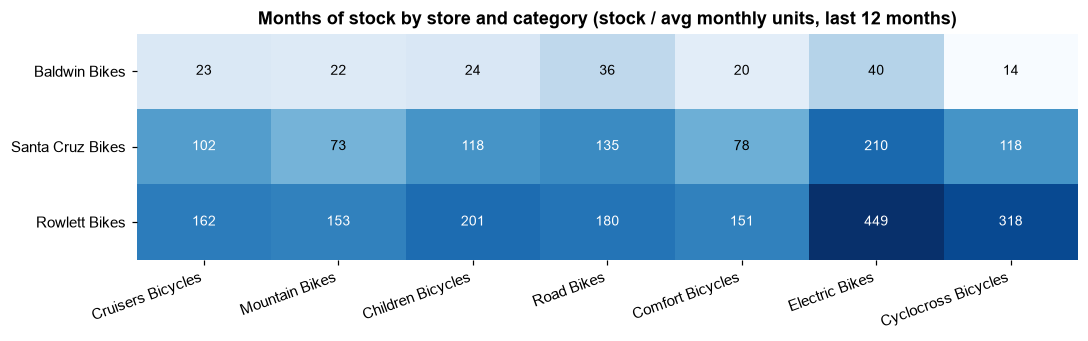

In [10]:
last_12m = sales[sales["order_date"] >= "2017-04-01"]
sold_12m = last_12m.pivot_table(index="store_name", columns="category_name",
                                values="quantity", aggfunc="sum", fill_value=0)
on_hand = stock.pivot_table(index="store_name", columns="category_name",
                            values="quantity", aggfunc="sum", fill_value=0)
cover = on_hand / (sold_12m / 12).replace(0, np.nan)   # months of stock
order = ["Baldwin Bikes", "Santa Cruz Bikes", "Rowlett Bikes"]
cover = cover.loc[order, on_hand.sum().sort_values(ascending=False).index]
display(cover.round(1))

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(np.log10(cover.values), cmap="Blues", aspect="auto")
ax.set_xticks(range(cover.shape[1]), cover.columns, rotation=20, ha="right")
ax.set_yticks(range(cover.shape[0]), cover.index)
for i in range(cover.shape[0]):
    for j in range(cover.shape[1]):
        val = cover.values[i, j]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center",
                color="white" if val > 100 else "black", fontsize=9)
ax.set_title("Months of stock by store and category (stock / avg monthly units, last 12 months)")
ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(CHARTS / "05_months_of_stock.png", bbox_inches="tight")
plt.show()

**Result:** Baldwin Bikes holds about 14-40 months of stock per category. Santa Cruz holds 73-210 months and Rowlett 151-449 months. Electric Bikes in Rowlett (449 months, over 37 years) is the most extreme case. The problem is the same in every category, so it comes from how stock is split between stores, not from one product line.

In [11]:
# What if total stock were split in line with each store's sales (last 12 months)?
units_12m = last_12m.groupby("store_name")["quantity"].sum()
current = stock.groupby("store_name")["quantity"].sum()
target = (units_12m / units_12m.sum() * current.sum()).round()

rebalance = pd.DataFrame({
    "units_sold_12m": units_12m,
    "current_stock": current,
    "stock_if_split_by_sales": target,
    "units_to_move": target - current,
}).loc[order]
rebalance["months_of_stock_now"] = rebalance["current_stock"] / (rebalance["units_sold_12m"] / 12)
rebalance["months_of_stock_after"] = rebalance["stock_if_split_by_sales"] / (rebalance["units_sold_12m"] / 12)
display(rebalance.round(1))
print(f"Units to move out of Santa Cruz and Rowlett: {-rebalance['units_to_move'].clip(upper=0).sum():,.0f}")

,units_sold_12m,current_stock,stock_if_split_by_sales,units_to_move,months_of_stock_now,months_of_stock_after
store_name,,,,,,
Baldwin Bikes,2110,4359,"9,687.00","5,328.00",24.80,55.10
Santa Cruz Bikes,527,4532,"2,419.00","-2,113.00",103.20,55.10
Rowlett Bikes,306,4620,"1,405.00","-3,215.00",181.20,55.10


Units to move out of Santa Cruz and Rowlett: 5,328


**Result (scenario):** if the current 13,511 units were split in line with each store's sales, **5,328 units would move to Baldwin Bikes** (2,113 from Santa Cruz and 3,215 from Rowlett). Every store would then hold the same 55 months of stock. Total stock would still be high, so rebalancing helps Baldwin but does not remove the overstock.

In [12]:
# Stock value by model year vs what sold in the last 12 months
age = pd.DataFrame({
    "stock_units": stock.groupby("model_year")["quantity"].sum(),
    "stock_value": stock.groupby("model_year")["stock_value"].sum(),
    "units_sold_12m": last_12m.groupby("model_year")["quantity"].sum(),
}).fillna(0)
age["pct_stock_value"] = age["stock_value"] / age["stock_value"].sum()
age["months_of_stock"] = age["stock_units"] / (age["units_sold_12m"] / 12).replace(0, np.nan)
display(age)

no_sale = stock[(stock["quantity"] > 0) & ~stock["product_id"].isin(last_12m["product_id"])]
print(f"Stocked products with no sale in the last 12 months: {no_sale['product_id'].nunique()} products, "
      f"{no_sale['quantity'].sum():,} units, ${no_sale['stock_value'].sum():,.0f}")

,stock_units,stock_value,units_sold_12m,pct_stock_value,months_of_stock
model_year,,,,,
2016,1046,"987,113.07",571,0.05,21.98
2017,3787,"4,428,514.13",1918,0.22,23.69
2018,8678,"14,403,955.45",454,0.73,229.37


Stocked products with no sale in the last 12 months: 35 products, 1,447 units, $2,215,816


**Result:** 2018 models hold **73% of stock value ($14.4M)** but sold only 454 units in the last 12 months (229 months of stock). Part of this is normal, because 2018 models were still new when the data ends. In addition, 35 stocked products ($2.2M) did not sell at all in the last 12 months. These are the first candidates for clearance.

## 4. Do bigger discounts sell more? (Q7)

Every order line has one of four discount levels (5%, 7%, 10% or 20%). A **permutation test** checks whether lines with a 20% discount sell more units than lines with a 5% discount. The labels are shuffled 10,000 times to see how large a difference random chance alone produces.

,lines,avg_units,discount_cost
discount,,,
0.05,1078,1.52,"98,164.40"
0.07,1026,1.49,"130,986.81"
0.10,1026,1.48,"174,452.79"
0.20,1084,1.50,"371,790.82"


Avg units per line: 20% discount = 1.500, 5% discount = 1.521
Difference = -0.021 units, permutation p-value = 0.32


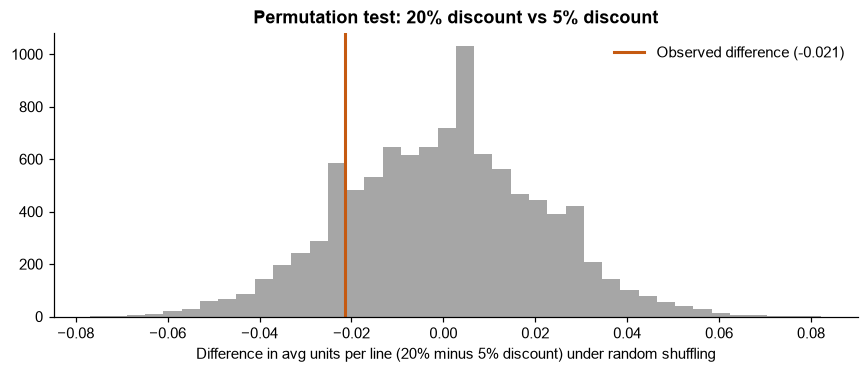

In [13]:
# Does a bigger discount sell more units? Permutation test with numpy
by_disc = sales.groupby("discount").agg(lines=("quantity", "size"), avg_units=("quantity", "mean"),
                                        discount_cost=("discount_amount", "sum"))
display(by_disc)

high = sales.loc[sales["discount"] == 0.20, "quantity"].values
low = sales.loc[sales["discount"] == 0.05, "quantity"].values
observed = high.mean() - low.mean()

rng = np.random.default_rng(42)
pooled = np.concatenate([high, low])
diffs = np.empty(10_000)
for k in range(diffs.size):
    rng.shuffle(pooled)
    diffs[k] = pooled[:high.size].mean() - pooled[high.size:].mean()
p_value = np.mean(np.abs(diffs) >= abs(observed))

print(f"Avg units per line: 20% discount = {high.mean():.3f}, 5% discount = {low.mean():.3f}")
print(f"Difference = {observed:+.3f} units, permutation p-value = {p_value:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(diffs, bins=40, color=GREY)
ax.axvline(observed, color=ORANGE, lw=2, label=f"Observed difference ({observed:+.3f})")
ax.set_xlabel("Difference in avg units per line (20% minus 5% discount) under random shuffling")
ax.set_title("Permutation test: 20% discount vs 5% discount")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(CHARTS / "06_discount_test.png", bbox_inches="tight")
plt.show()

**Result:** lines with a 20% discount sell **no more units** than lines with a 5% discount (1.50 vs 1.52 units, p = 0.32). The 20% level costs $372K, which is 48% of all discount cost, with no measurable gain in volume. Discount levels should be reviewed, keeping in mind that the discounts in this sample data look randomly assigned.

## 5. Basket analysis: categories bought together

Each order is turned into a yes/no row per category. **Lift** compares how often two categories appear together with what chance alone would give (lift above 1 = bought together more often than chance).

In [14]:
# Which categories are bought together in the same order?
basket = (sales.groupby(["order_id", "category_name"]).size().unstack(fill_value=0) > 0).astype(int)
co = basket.T.dot(basket)                      # orders containing both categories
support = np.diag(co) / len(basket)            # share of orders containing each category
pair_share = co / len(basket)
lift = pair_share / np.outer(support, support)

multi = (basket.sum(axis=1) > 1).mean()
print(f"Orders with more than one category: {multi:.1%}")

pairs = (pd.DataFrame({"orders_together": co.where(np.triu(np.ones(co.shape), 1).astype(bool)).stack(),
                       "lift": lift.where(np.triu(np.ones(co.shape), 1).astype(bool)).stack()})
         .sort_values("orders_together", ascending=False))
display(pairs.head(8))

Orders with more than one category: 76.1%


orders_together  lift
category_name     category_name                             
Cruisers Bicycles Mountain Bikes                453.00  0.96
Children Bicycles Cruisers Bicycles             320.00  0.95
                  Mountain Bikes                262.00  0.85
Comfort Bicycles  Cruisers Bicycles             228.00  0.90
                  Mountain Bikes                225.00  0.97
Children Bicycles Comfort Bicycles              150.00  0.91
Cruisers Bicycles Cyclocross Bicycles           130.00  0.95
                  Road Bikes                    128.00  0.85

In [15]:
# Order value by number of categories in the order
order_value = sales.groupby("order_id").agg(net_revenue=("net_revenue", "sum"),
                                            categories=("category_name", "nunique"))
display(order_value.groupby("categories")["net_revenue"].agg(["count", "mean", "median"]))

,count,mean,median
categories,,,
1,346,"1,868.82","1,022.98"
2,514,"4,115.42","3,115.99"
3,442,"6,180.48","5,120.85"
4,131,"7,806.75","7,179.98"
5,12,"12,184.70","12,311.12"


**Result:** 76% of orders contain more than one category, and order value rises with the number of categories (median $1,023 for one category, $5,121 for three). However, every category pair has a lift below 1, so no pair is bought together more often than chance. Customers buy several bikes per order, but there is no specific cross-selling pattern to target.

## Summary

| Area | Finding | Implication |
| --- | --- | --- |
| Growth | 2017 revenue +41%, with 55% of the growth came from mix (Road and Electric bikes), only 5% from price | Growth depends on premium categories, not on more customers |
| Products | 19% of products make 80% of revenue (Gini 0.76) | Protect stock of class A products and review the class C range |
| Stores | Baldwin sells 71% of revenue with 32% of stock, while Rowlett holds 181 months of stock | Move about 5,300 units towards Baldwin |
| Stock age | 2018 models are 73% of stock value, and 35 products ($2.2M) had no sale in 12 months | Plan clearance for non-moving products |
| Discounts | 20% discount sells no more units than 5% (p = 0.32) and costs 48% of all discounts | Reduce or target the 20% level |
| Baskets | 76% of orders are multi-category, but no pair is bought together more than chance | No specific cross-sell pair to promote |

**Limitations:** no cost data (no profit or margin), one completed order per customer (no retention analysis), and stock is a single undated snapshot.